1. Analisa: temukan at least 3 insight utama tentang siapa yang cenderung resign dan kenapa.

Jawaban:
- Masa kerja 1–3 tahun paling rawan resign: proporsinya 29,73%, dibanding 12,55% pada masa kerja ≥5 tahun.\
Proporsi resign mencapai 29,73%, dibandingkan 12,55% pada masa kerja ≥5 tahun. Salah satu kemungkinan alasannya adalah ketidaksesuaian ekspektasi pekerjaan atau peluang pengembangan karier pada fase awal bekerja. Dugaan ini perlu dikonfirmasi melalui exit interview karena alasan resign tidak tercatat dalam dataset.
- Supervisor memiliki proporsi resign tertinggi berdasarkan level: 20,70%, dibanding 6,52% pada Senior Manager.\
Proporsinya mencapai 20,70%, dibandingkan 6,52% pada Senior Manager. Kondisi ini dapat menjadi dasar untuk menelusuri apakah tuntutan operasional dan pengelolaan tim sudah diimbangi dukungan serta penghargaan yang memadai.
- Lembur lebih tinggi berkaitan dengan proporsi resign lebih besar: 10,75% pada kelompok 0–10 jam, meningkat menjadi 33,33% pada kelompok 31–40 jam.\
Korelasi lembur dengan resign sebesar +0,22, sedangkan korelasinya dengan engagement sebesar −0,23. Pola ini mengindikasikan bahwa beban kerja dan keterikatan karyawan perlu dievaluasi bersama sebagai kemungkinan faktor terkait resign.
- Sales & Distribution menyumbang resign terbanyak: 64 orang, atau 38,55% dari seluruh resign.\
Departemen ini menyumbang 64 orang atau 38,55% dari seluruh resign. Data sumber juga menunjukkan rata-rata lembur tertinggi, yaitu 14,18 jam/bulan, dan engagement terendah, yaitu 3,64. Kedua kondisi tersebut menjadi indikasi bahwa beban kerja dan keterikatan karyawan layak ditelusuri lebih lanjut untuk memahami tingginya jumlah resign.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from pathlib import Path

# Run locally from the repository root/notebooks folder, or from Colab after uploading Case.xlsx.
candidates = [Path('data/Case.xlsx'), Path('../data/Case.xlsx'), Path('/content/Case.xlsx')]
case_path = next((path for path in candidates if path.is_file()), None)
if case_path is None:
    raise FileNotFoundError('Case.xlsx not found. Place it in data/ or upload it to /content/ on Colab.')
data = pd.read_excel(case_path)
data.head(5)

,employee_id,department,level,age,Tenure,Salary ratio vs peers,Last year performance rating,months since last promotion,avg overtime hours per month,engagement score,status,resign_date
0,EMP0001,Sales & Distribution,Assistant Manager,38,5.9,1.04,3,71,18.3,2.9,Active,NaT
1,EMP0002,IT,Associate,36,5.9,1.05,4,22,7.4,3.3,Active,NaT
2,EMP0003,Operations,Assistant Manager,32,4.5,0.81,3,54,23.2,2.8,Resigned,2026-01-16
3,EMP0004,Operations,Supervisor,27,6.3,0.88,2,19,13.2,3.4,Active,NaT
4,EMP0005,Operations,Assistant Manager,31,3.7,0.75,3,45,15.8,4.1,Active,NaT


In [3]:
df = pd.DataFrame(data)
print(df)

    employee_id            department              level  age  Tenure  \
0       EMP0001  Sales & Distribution  Assistant Manager   38     5.9   
1       EMP0002                    IT          Associate   36     5.9   
2       EMP0003            Operations  Assistant Manager   32     4.5   
3       EMP0004            Operations         Supervisor   27     6.3   
4       EMP0005            Operations  Assistant Manager   31     3.7   
..          ...                   ...                ...  ...     ...   
995     EMP0996                    IT  Assistant Manager   34     6.6   
996     EMP0997               Finance         Supervisor   28     3.1   
997     EMP0998  Sales & Distribution          Associate   35     9.5   
998     EMP0999            Operations          Associate   28     2.3   
999     EMP1000            Operations  Assistant Manager   39     5.9   

     Salary ratio vs peers  Last year performance rating  \
0                     1.04                             3   
1  

In [4]:
numeric = df.select_dtypes(include="number").copy()
numeric["resigned_flag"] = df["status"].map({"Active": 0, "Resigned": 1})

corr = numeric.corr(method="pearson")
print(corr.round(3))

                                age  Tenure  Salary ratio vs peers  \
age                           1.000   0.764                 -0.001   
Tenure                        0.764   1.000                 -0.019   
Salary ratio vs peers        -0.001  -0.019                  1.000   
Last year performance rating  0.017   0.012                  0.029   
months since last promotion   0.084   0.077                 -0.003   
avg overtime hours per month  0.002  -0.050                  0.020   
engagement score             -0.065  -0.030                  0.057   
resigned_flag                -0.126  -0.127                 -0.266   

                              Last year performance rating  \
age                                                  0.017   
Tenure                                               0.012   
Salary ratio vs peers                                0.029   
Last year performance rating                         1.000   
months since last promotion                         -0.039 

In [5]:
corr_with_resign = corr["resigned_flag"].drop("resigned_flag")
print(corr_with_resign.sort_values(key=abs, ascending=False).round(3))

Salary ratio vs peers          -0.266
avg overtime hours per month    0.223
engagement score               -0.206
Tenure                         -0.127
age                            -0.126
months since last promotion     0.068
Last year performance rating   -0.003
Name: resigned_flag, dtype: float64


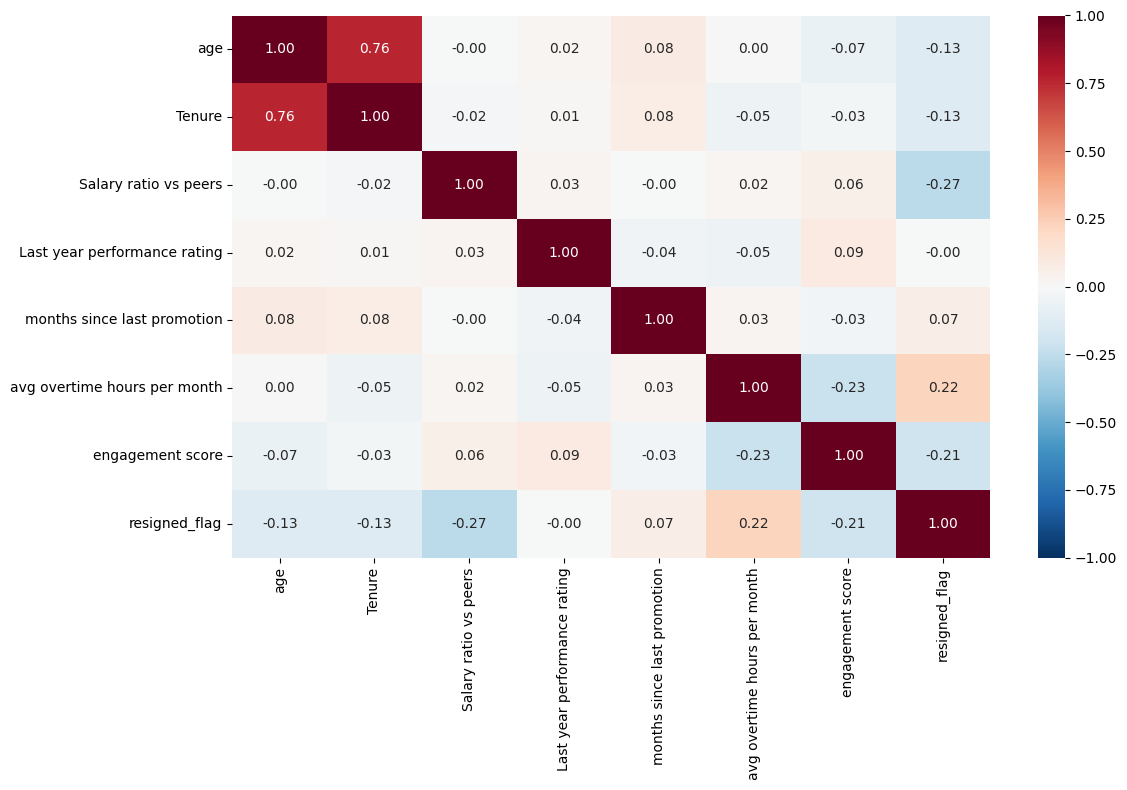

In [6]:
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.tight_layout()
plt.show()

In [7]:
y = df["status"].map({"Active": 0, "Resigned": 1})

In [8]:
case_features = ['department','level','age','Tenure','Salary ratio vs peers','Last year performance rating','months since last promotion','avg overtime hours per month','engagement score']
x = df[case_features]

In [9]:
x.describe()

,age,Tenure,Salary ratio vs peers,Last year performance rating,months since last promotion,avg overtime hours per month,engagement score
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,32.601000,5.52090,0.998810,3.282000,27.707000,12.205500,3.713900
std,5.217952,2.99296,0.109517,0.653378,21.966968,8.680355,0.598193
min,21.000000,0.50000,0.720000,1.000000,2.000000,0.000000,1.800000
25%,29.000000,3.30000,0.920000,3.000000,11.000000,6.100000,3.300000
50%,32.000000,5.00000,1.000000,3.000000,22.000000,10.550000,3.700000
75%,36.000000,7.10000,1.070000,4.000000,39.000000,16.300000,4.100000
max,51.000000,20.60000,1.350000,5.000000,150.000000,54.700000,5.000000


In [10]:
x.head()

,department,level,age,Tenure,Salary ratio vs peers,Last year performance rating,months since last promotion,avg overtime hours per month,engagement score
0,Sales & Distribution,Assistant Manager,38,5.9,1.04,3,71,18.3,2.9
1,IT,Associate,36,5.9,1.05,4,22,7.4,3.3
2,Operations,Assistant Manager,32,4.5,0.81,3,54,23.2,2.8
3,Operations,Supervisor,27,6.3,0.88,2,19,13.2,3.4
4,Operations,Assistant Manager,31,3.7,0.75,3,45,15.8,4.1


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix,precision_score, recall_score,f1_score,roc_curve, roc_auc_score
from sklearn.compose import make_column_transformer, make_column_selector

In [12]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.20, random_state=29, stratify=y
)

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_cols = ["department", "level"]
numeric_cols = x_train.select_dtypes(include="number").columns.tolist()

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_cols),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
])

x_train_ready = preprocessor.fit_transform(x_train)
x_test_ready = preprocessor.transform(x_test)

In [14]:
split_summary = pd.DataFrame({
    "Bagian data": ["Training untuk CV", "Test set"],
    "Total karyawan": [len(y_train), len(y_test)],
    "Active (0)": [int((y_train == 0).sum()), int((y_test == 0).sum())],
    "Resigned (1)": [int((y_train == 1).sum()), int((y_test == 1).sum())]
}).set_index("Bagian data")
display(split_summary)

,Total karyawan,Active (0),Resigned (1)
Bagian data,,,
Training untuk CV,800,667,133
Test set,200,167,33


In [15]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, accuracy_score, precision_score, recall_score,
    f1_score, fbeta_score, confusion_matrix, roc_auc_score,
    average_precision_score, RocCurveDisplay
)
from matplotlib.colors import ListedColormap

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)
metric_columns = ["Accuracy", "Precision Resigned", "Recall Resigned", "F1 Resigned", "F2 Resigned"]


def prediction_metrics(actual, predicted, probability):
    tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()
    return {
        "Accuracy": accuracy_score(actual, predicted),
        "Precision Resigned": precision_score(actual, predicted, zero_division=0),
        "Recall Resigned": recall_score(actual, predicted, zero_division=0),
        "F1 Resigned": f1_score(actual, predicted, zero_division=0),
        "F2 Resigned": fbeta_score(actual, predicted, beta=2, zero_division=0),
        "ROC AUC": roc_auc_score(actual, probability),
        "Average Precision": average_precision_score(actual, probability),
        "TP": int(tp), "FN": int(fn), "FP": int(fp), "TN": int(tn)
    }


def show_evaluation(actual, predicted, probability, title):
    print(title)
    print(f"Total: {len(actual)} karyawan | Active: {int((actual == 0).sum())} | Resigned: {int((actual == 1).sum())}")
    print(classification_report(
        actual, predicted, labels=[0, 1], target_names=["Active", "Resigned"],
        digits=3, zero_division=0
    ))
    result = prediction_metrics(actual, predicted, probability)
    print(f"Accuracy: {result['Accuracy']:.3f} | F2 Resigned: {result['F2 Resigned']:.3f}")
    print(f"ROC AUC: {result['ROC AUC']:.3f} | Average Precision: {result['Average Precision']:.3f}")
    print(f"Resign terdeteksi (TP): {result['TP']} | Resign terlewat (FN): {result['FN']} | Active ditandai resign (FP): {result['FP']}")

    cm = confusion_matrix(actual, predicted, labels=[0, 1])
    row_pct = np.divide(cm, cm.sum(axis=1, keepdims=True),
                        out=np.zeros_like(cm, dtype=float),
                        where=cm.sum(axis=1, keepdims=True) != 0)
    annotations = [
        [f"{count}\n{pct:.1%}" for count, pct in zip(counts, percentages)]
        for counts, percentages in zip(cm, row_pct)
    ]
    fig, ax = plt.subplots(figsize=(7, 4.5))
    sns.heatmap(
        [[0, 1], [2, 0]], annot=annotations, fmt="",
        cmap=ListedColormap(["#DCEAFB", "#FCEFE5", "#F9C994"]),
        cbar=False, linewidths=3, linecolor="white",
        xticklabels=["Active", "Resigned"], yticklabels=["Active", "Resigned"],
        annot_kws={"fontsize": 15, "color": "#152841"}, ax=ax
    )
    ax.set(title=title + f"\nn={len(actual)}; persen per status aktual",
           xlabel="Prediksi model", ylabel="Status aktual")
    ax.tick_params(axis="y", labelrotation=0)
    plt.tight_layout()
    plt.show()
    return result


def run_stratified_cv(estimator):
    oof_probability = np.full(len(y_train), np.nan)
    fold_number = np.zeros(len(y_train), dtype=int)
    coverage = np.zeros(len(y_train), dtype=int)
    scaler_sample_counts = []
    for fold, (train_index, valid_index) in enumerate(cv.split(x_train, y_train), start=1):
        fold_pipeline = Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("classifier", clone(estimator))
        ])
        fold_pipeline.fit(x_train.iloc[train_index], y_train.iloc[train_index])
        positive_column = list(fold_pipeline.classes_).index(1)
        oof_probability[valid_index] = fold_pipeline.predict_proba(
            x_train.iloc[valid_index]
        )[:, positive_column]
        fold_number[valid_index] = fold
        coverage[valid_index] += 1
        scaler_sample_counts.append(int(
            fold_pipeline.named_steps["preprocessor"].named_transformers_["numeric"].n_samples_seen_
        ))
    return {"probability": oof_probability, "fold": fold_number,
            "coverage": coverage, "scaler_sample_counts": scaler_sample_counts}


def cv_scores_at_threshold(cv_result, threshold):
    rows = []
    for fold in range(1, cv.n_splits + 1):
        mask = cv_result["fold"] == fold
        probability = cv_result["probability"][mask]
        predicted = (probability > threshold).astype(int)
        rows.append({"Fold": fold, **prediction_metrics(y_train.iloc[mask], predicted, probability)})
    return pd.DataFrame(rows).set_index("Fold")


def show_cv_tables(cv_result, threshold):
    scores = cv_scores_at_threshold(cv_result, threshold)
    print(f"CV TRAINING | threshold={threshold:.2f} | skor per fold")
    display(scores[metric_columns].round(3))
    print("Rata-rata dan SD antar-fold, bukan skor test set")
    display(scores[metric_columns].agg(["mean", "std"]).rename(
        index={"mean": "Rata-rata CV", "std": "SD antar-fold"}
    ).round(3))
    return scores

# Logistic Regression

TEST SET | Logres | threshold=0.50
Total: 200 karyawan | Active: 167 | Resigned: 33
              precision    recall  f1-score   support

      Active      0.856     0.964     0.907       167
    Resigned      0.500     0.182     0.267        33

    accuracy                          0.835       200
   macro avg      0.678     0.573     0.587       200
weighted avg      0.798     0.835     0.801       200

Accuracy: 0.835 | F2 Resigned: 0.208
ROC AUC: 0.829 | Average Precision: 0.532
Resign terdeteksi (TP): 6 | Resign terlewat (FN): 27 | Active ditandai resign (FP): 6


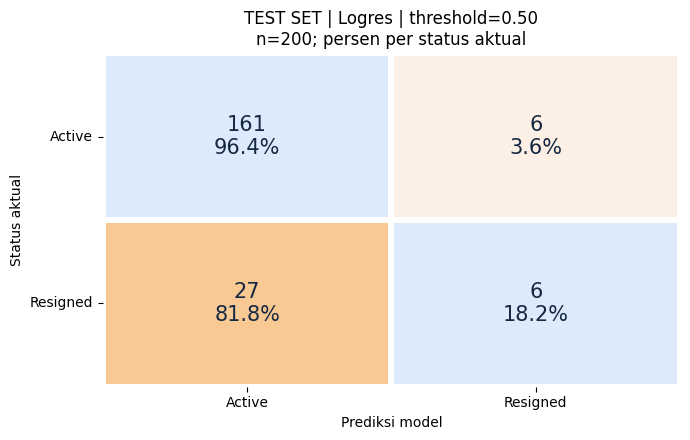

In [16]:
model = LogisticRegression(max_iter=1000)
model.fit(x_train_ready, y_train)

y_pred = model.predict(x_test_ready)
y_prob = model.predict_proba(x_test_ready)[:, list(model.classes_).index(1)]
logres_default_test = show_evaluation(
    y_test, y_pred, y_prob, "TEST SET | Logres | threshold=0.50"
)

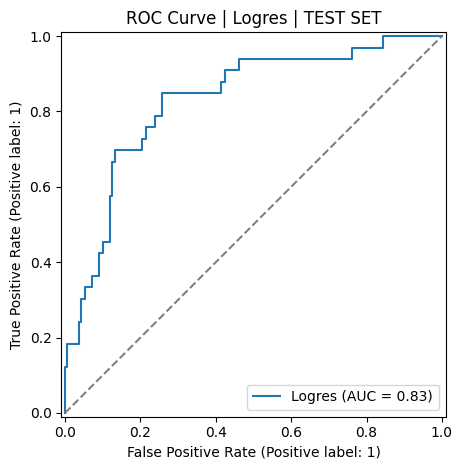

In [17]:
RocCurveDisplay.from_predictions(y_test, y_prob, name="Logres")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.title("ROC Curve | Logres | TEST SET")
plt.tight_layout()
plt.show()

CV TRAINING | threshold=0.50 | skor per fold


,Accuracy,Precision Resigned,Recall Resigned,F1 Resigned,F2 Resigned
Fold,,,,,
1,0.825,0.438,0.269,0.333,0.292
2,0.831,0.444,0.154,0.229,0.177
3,0.844,0.583,0.259,0.359,0.292
4,0.888,0.909,0.370,0.526,0.420
5,0.862,0.727,0.296,0.421,0.336


Rata-rata dan SD antar-fold, bukan skor test set


,Accuracy,Precision Resigned,Recall Resigned,F1 Resigned,F2 Resigned
Rata-rata CV,0.850,0.62,0.270,0.374,0.303
SD antar-fold,0.025,0.20,0.078,0.110,0.088


CV VALIDASI OOF | Logres | threshold=0.50
Total: 800 karyawan | Active: 667 | Resigned: 133
              precision    recall  f1-score   support

      Active      0.869     0.966     0.915       667
    Resigned      0.610     0.271     0.375       133

    accuracy                          0.850       800
   macro avg      0.740     0.618     0.645       800
weighted avg      0.826     0.850     0.825       800

Accuracy: 0.850 | F2 Resigned: 0.305
ROC AUC: 0.795 | Average Precision: 0.475
Resign terdeteksi (TP): 36 | Resign terlewat (FN): 97 | Active ditandai resign (FP): 23


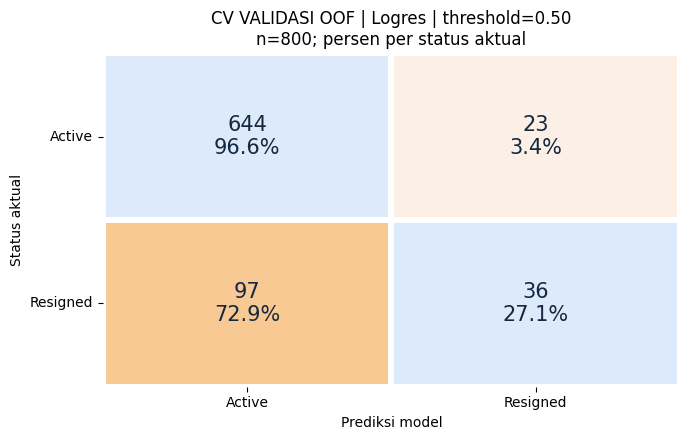

In [18]:
cv_logres = run_stratified_cv(model)
cv_logres_default_scores = show_cv_tables(cv_logres, threshold=0.50)
y_pred_logres_oof = (cv_logres["probability"] > 0.50).astype(int)
logres_default_oof = show_evaluation(
    y_train, y_pred_logres_oof, cv_logres["probability"],
    "CV VALIDASI OOF | Logres | threshold=0.50"
)

Resign kurang bisa dideteksi maka akan coba dibuat lebih sensitif

TEST SET | Logres | threshold=0.10
Total: 200 karyawan | Active: 167 | Resigned: 33
              precision    recall  f1-score   support

      Active      0.969     0.557     0.707       167
    Resigned      0.288     0.909     0.438        33

    accuracy                          0.615       200
   macro avg      0.629     0.733     0.573       200
weighted avg      0.857     0.615     0.663       200

Accuracy: 0.615 | F2 Resigned: 0.636
ROC AUC: 0.829 | Average Precision: 0.532
Resign terdeteksi (TP): 30 | Resign terlewat (FN): 3 | Active ditandai resign (FP): 74


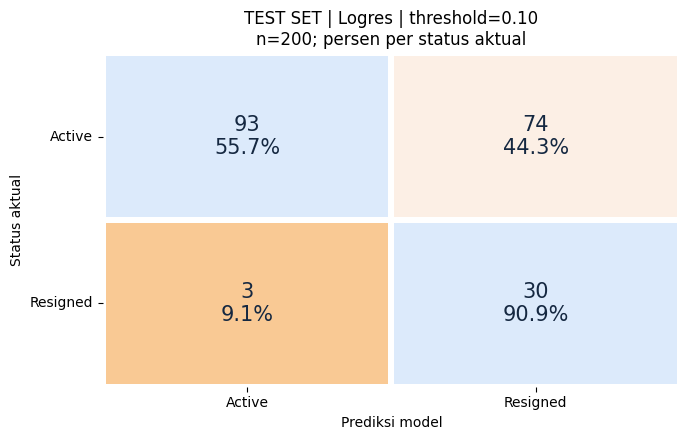

In [19]:
threshold_logres = 0.10
y_pred_logres_threshold = (y_prob > threshold_logres).astype(int)

logres_threshold_test = show_evaluation(
    y_test, y_pred_logres_threshold, y_prob,
    f"TEST SET | Logres | threshold={threshold_logres:.2f}"
)

In [20]:
cv_logres_threshold_scores = show_cv_tables(cv_logres, threshold=threshold_logres)

CV TRAINING | threshold=0.10 | skor per fold


,Accuracy,Precision Resigned,Recall Resigned,F1 Resigned,F2 Resigned
Fold,,,,,
1,0.631,0.268,0.731,0.392,0.543
2,0.638,0.289,0.846,0.431,0.611
3,0.544,0.244,0.815,0.376,0.556
4,0.688,0.342,0.926,0.500,0.691
5,0.600,0.277,0.852,0.418,0.602


Rata-rata dan SD antar-fold, bukan skor test set


,Accuracy,Precision Resigned,Recall Resigned,F1 Resigned,F2 Resigned
Rata-rata CV,0.620,0.284,0.834,0.423,0.600
SD antar-fold,0.053,0.036,0.071,0.048,0.058


Resign dapat lebih sering terdeteksi namun akurasi secara garis besar menurun

# Random Forest

TEST SET | RF | threshold=0.50
Total: 200 karyawan | Active: 167 | Resigned: 33
              precision    recall  f1-score   support

      Active      0.898     0.952     0.924       167
    Resigned      0.652     0.455     0.536        33

    accuracy                          0.870       200
   macro avg      0.775     0.703     0.730       200
weighted avg      0.858     0.870     0.860       200

Accuracy: 0.870 | F2 Resigned: 0.484
ROC AUC: 0.825 | Average Precision: 0.481
Resign terdeteksi (TP): 15 | Resign terlewat (FN): 18 | Active ditandai resign (FP): 8


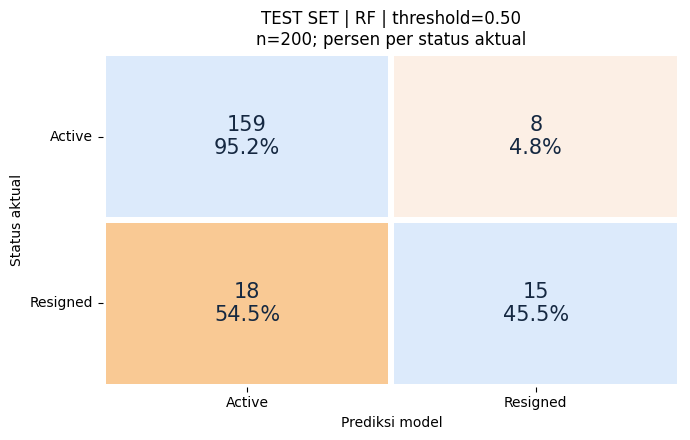

In [21]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=3,
    class_weight="balanced_subsample",
    random_state=29,
    n_jobs=-1
)
rf_model.fit(x_train_ready, y_train)

y_pred_rf = rf_model.predict(x_test_ready)
y_proba_rf = rf_model.predict_proba(x_test_ready)[:, list(rf_model.classes_).index(1)]
rf_default_test = show_evaluation(
    y_test, y_pred_rf, y_proba_rf, "TEST SET | RF | threshold=0.50"
)

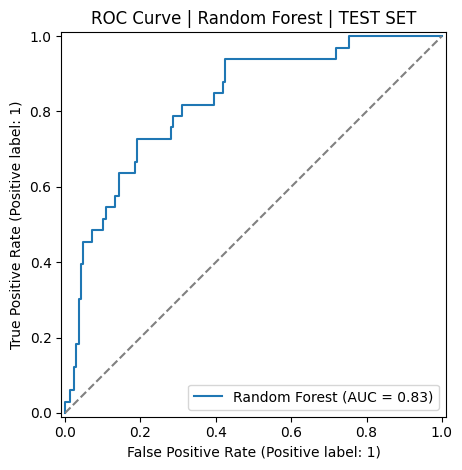

In [22]:
RocCurveDisplay.from_predictions(y_test, y_proba_rf, name="Random Forest")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.title("ROC Curve | Random Forest | TEST SET")
plt.tight_layout()
plt.show()

CV TRAINING | threshold=0.50 | skor per fold


,Accuracy,Precision Resigned,Recall Resigned,F1 Resigned,F2 Resigned
Fold,,,,,
1,0.812,0.389,0.269,0.318,0.287
2,0.838,0.500,0.231,0.316,0.259
3,0.875,0.684,0.481,0.565,0.512
4,0.875,0.667,0.519,0.583,0.543
5,0.831,0.500,0.296,0.372,0.323


Rata-rata dan SD antar-fold, bukan skor test set


,Accuracy,Precision Resigned,Recall Resigned,F1 Resigned,F2 Resigned
Rata-rata CV,0.846,0.548,0.359,0.431,0.385
SD antar-fold,0.028,0.125,0.131,0.133,0.133


CV VALIDASI OOF | RF | threshold=0.50
Total: 800 karyawan | Active: 667 | Resigned: 133
              precision    recall  f1-score   support

      Active      0.881     0.943     0.911       667
    Resigned      0.558     0.361     0.438       133

    accuracy                          0.846       800
   macro avg      0.720     0.652     0.675       800
weighted avg      0.827     0.846     0.832       800

Accuracy: 0.846 | F2 Resigned: 0.388
ROC AUC: 0.789 | Average Precision: 0.459
Resign terdeteksi (TP): 48 | Resign terlewat (FN): 85 | Active ditandai resign (FP): 38


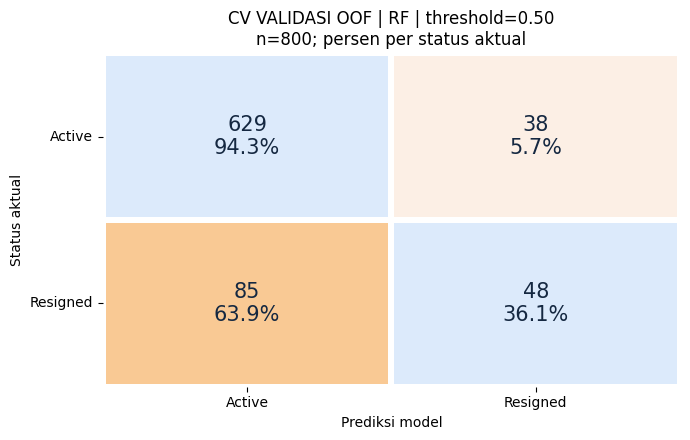

In [23]:
cv_rf = run_stratified_cv(rf_model)
cv_rf_default_scores = show_cv_tables(cv_rf, threshold=0.50)
y_pred_rf_oof = (cv_rf["probability"] > 0.50).astype(int)
rf_default_oof = show_evaluation(
    y_train, y_pred_rf_oof, cv_rf["probability"],
    "CV VALIDASI OOF | RF | threshold=0.50"
)

Sama kasus seperti Logistic Regression

TEST SET | RF | threshold=0.20
Total: 200 karyawan | Active: 167 | Resigned: 33
              precision    recall  f1-score   support

      Active      0.960     0.581     0.724       167
    Resigned      0.293     0.879     0.439        33

    accuracy                          0.630       200
   macro avg      0.627     0.730     0.582       200
weighted avg      0.850     0.630     0.677       200

Accuracy: 0.630 | F2 Resigned: 0.628
ROC AUC: 0.825 | Average Precision: 0.481
Resign terdeteksi (TP): 29 | Resign terlewat (FN): 4 | Active ditandai resign (FP): 70


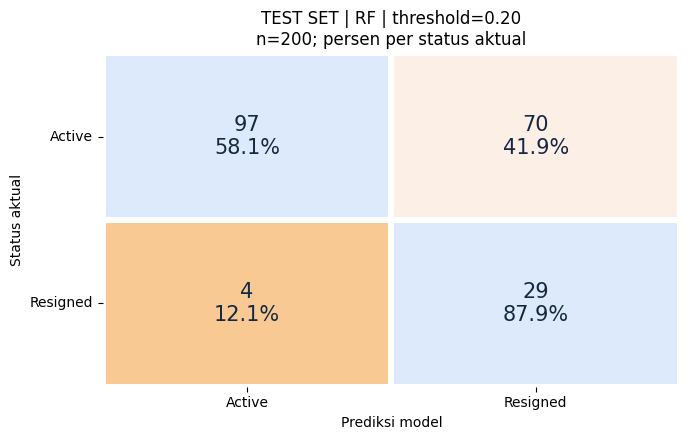

In [24]:
threshold_rf = 0.20
y_pred_rf_threshold = (y_proba_rf > threshold_rf).astype(int)

rf_threshold_test = show_evaluation(
    y_test, y_pred_rf_threshold, y_proba_rf,
    f"TEST SET | RF | threshold={threshold_rf:.2f}"
)

In [25]:
cv_rf_threshold_scores = show_cv_tables(cv_rf, threshold=threshold_rf)

CV TRAINING | threshold=0.20 | skor per fold


,Accuracy,Precision Resigned,Recall Resigned,F1 Resigned,F2 Resigned
Fold,,,,,
1,0.612,0.263,0.769,0.392,0.556
2,0.638,0.278,0.769,0.408,0.568
3,0.544,0.244,0.815,0.376,0.556
4,0.675,0.333,0.926,0.490,0.683
5,0.600,0.272,0.815,0.407,0.582


Rata-rata dan SD antar-fold, bukan skor test set


,Accuracy,Precision Resigned,Recall Resigned,F1 Resigned,F2 Resigned
Rata-rata CV,0.614,0.278,0.819,0.415,0.589
SD antar-fold,0.048,0.033,0.064,0.044,0.054


Berhasil mendeteksi lebih konsisten namun akurasi menurun seperti Logistic Regression juga

# Perbandingan

In [26]:
test_summary = pd.DataFrame({
    "Logres | 0.50": logres_default_test,
    "Logres | 0.10": logres_threshold_test,
    "RF | 0.50": rf_default_test,
    "RF | 0.20": rf_threshold_test
}).T
test_summary[["TP", "FN", "FP", "TN"]] = test_summary[["TP", "FN", "FP", "TN"]].astype(int)
print("TEST SET | 200 karyawan, termasuk 33 Resigned")
display(test_summary[metric_columns + ["TP", "FN", "FP", "TN"]].round(3))

cv_score_tables = {
    "Logres | 0.50": cv_logres_default_scores,
    "Logres | 0.10": cv_logres_threshold_scores,
    "RF | 0.50": cv_rf_default_scores,
    "RF | 0.20": cv_rf_threshold_scores
}
cv_summary = pd.DataFrame({
    name: {
        metric: f"{scores[metric].mean():.3f} ± {scores[metric].std(ddof=1):.3f}"
        for metric in metric_columns
    }
    for name, scores in cv_score_tables.items()
}).T
print("CV TRAINING | rata-rata ± SD lima fold pada 800 karyawan training")
display(cv_summary)

TEST SET | 200 karyawan, termasuk 33 Resigned


,Accuracy,Precision Resigned,Recall Resigned,F1 Resigned,F2 Resigned,TP,FN,FP,TN
Logres | 0.50,0.835,0.500,0.182,0.267,0.208,6,27,6,161
Logres | 0.10,0.615,0.288,0.909,0.438,0.636,30,3,74,93
RF | 0.50,0.870,0.652,0.455,0.536,0.484,15,18,8,159
RF | 0.20,0.630,0.293,0.879,0.439,0.628,29,4,70,97


CV TRAINING | rata-rata ± SD lima fold pada 800 karyawan training


,Accuracy,Precision Resigned,Recall Resigned,F1 Resigned,F2 Resigned
Logres | 0.50,0.850 ± 0.025,0.620 ± 0.200,0.270 ± 0.078,0.374 ± 0.110,0.303 ± 0.088
Logres | 0.10,0.620 ± 0.053,0.284 ± 0.036,0.834 ± 0.071,0.423 ± 0.048,0.600 ± 0.058
RF | 0.50,0.846 ± 0.028,0.548 ± 0.125,0.359 ± 0.131,0.431 ± 0.133,0.385 ± 0.133
RF | 0.20,0.614 ± 0.048,0.278 ± 0.033,0.819 ± 0.064,0.415 ± 0.044,0.589 ± 0.054


Penurunan threshold dapat meningkatkan recall sekaligus menambah false positive dan menurunkan accuracy atau precision